# **1. Imports and Setup**

### 1.1. Install W&B and load **ALL** the imports

In [ ]:
!pip install -q wandb

from PIL import Image
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, recall_score, precision_score, roc_auc_score
from tensorflow import keras
from tensorflow.keras import layers
from skimage.feature import hog
from sklearn.metrics import accuracy_score
from collections import Counter
from tqdm.auto import tqdm
import os, random, zipfile, sklearn, wandb, joblib
from pathlib import Path
from sklearn.model_selection import train_test_split
import pandas as pd
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, classification_report
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from google.colab import drive

### 1.2. Set random seed and W&B to offline mode to keep runs on disk

In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

os.environ["WANDB_MODE"] = "offline"

### 1.3. Mounts Drive and creates the folders. Drive is for saving the outputs, models, and wandb. `work_dir` is on Colab's local disk for faster reads simply because Colab's runtime is considerably faster than reading from Google drive.

In [ ]:
drive.mount('/content/drive')

base_dir = Path('/content/drive/MyDrive/summative')
folder_names = ['data/raw', 'data/processed', 'models', 'notebooks', 'outputs']
for name in folder_names:
    (base_dir / name).mkdir(parents=True, exist_ok=True)

raw_dir = base_dir / 'data' / 'raw'
processed_dir = base_dir / 'data' / 'processed'
notebook_dir = base_dir / 'notebooks'
model_dir = base_dir / 'models'
output_dir = base_dir / 'outputs'

# Fast local disk for extracted images. It does reset every session though
work_dir = Path('/content/work')
work_dir.mkdir(exist_ok=True)
print(base_dir, work_dir)

Mounted at /content/drive
/content/drive/MyDrive/summative /content/work


The output confirms that Drive is mounted and shows the two storage locations: the project root on Drive for durable files (models, outputs, processed data) and a separate local work folder for the extracted images. Reading thousands of images from Drive is slow, so this split keeps training fast while a runtime reset only costs the images, which can be downloaded again.

# **2. Download and Explore CCMT Images**


### 2.1. This contains reusable helper functions that perform the following purposes: look inside a zip, extract only what I want because they also contain the augmented images of which are no use to me, then finally count the images per folder

In [ ]:
IMG_EXTS = {'.jpg', '.jpeg', '.png'}

def summarize_zip(zip_path, depth=2):
    with zipfile.ZipFile(zip_path) as zf:
        names = [n for n in zf.namelist() if not n.endswith("/")]
    counts = Counter("/".join(n.split("/")[:depth]) for n in names)
    return names, counts

def extract_matching(zip_path, dest, keep):
    dest = Path(dest)
    dest.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path) as zf:
        members = [n for n in zf.namelist() if not n.endswith("/") and keep(n)]
        for name in tqdm(members, desc="Extracting"):
            zf.extract(name, dest)
    return len(members)

def count_images(root):
    counts = Counter()
    for p in Path(root).rglob("*"):
        if p.suffix.lower() in IMG_EXTS:
            counts[p.parent.name] += 1
    return counts

This cell defines the reusable helpers for peeking inside a zip, extracting only the files that pass a rule, and counting images per folder. Writing them as functions avoids repeating the same logic for CCMT and rice. Downloads in this notebook are done with wget instead of a helper function.

### 2.2. Downloading and extracting the CCMT data (Cashew, Cassava, Maize, Tomato). This also check the size and if it's a valid zip

In [ ]:
!wget -O /content/work/ccmt.zip "https://data.mendeley.com/public-api/zip/bwh3zbpkpv/download/1"
ccmt_zip = work_dir / "ccmt.zip"
print(f"{ccmt_zip.stat().st_size / 1e9:.2f} GB, valid zip: {zipfile.is_zipfile(ccmt_zip)}")

--2026-10-17 09:42:15--  https://data.mendeley.com/public-api/zip/bwh3zbpkpv/download/1
Resolving data.mendeley.com (data.mendeley.com)... 162.159.133.86, 162.159.130.86
Connecting to data.mendeley.com (data.mendeley.com)|162.159.133.86|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://prod-dcd-datasets-cache-zipfiles.s3.eu-west-1.amazonaws.com/bwh3zbpkpv-1.zip?X-Amz-Security-Token=IQoJb3JpZ2luX2VjEDIaCWV1LXdlc3QtMSJHMEUCID%2BLxetIQQItxjx2fO2U0bR3fYyI30EfD4GFpEhzoBVGAiEA0dZbmFLzspdCDMRtpmpzaPkO4KX4dcifbkmwqBV6HlAqlQUI%2Bv%2F%2F%2F%2F%2F%2F%2F%2F%2F%2FARAEGgwzNjcxNDczODM4MjUiDMX8p1t5KsJku2pT%2FSrpBMbyhlAWSr%2BOjhDY0izpsXSGDW9SS1k5YVAXgNxVPv%2BYqvzhFiMGCi16TaDH%2BDixzSDzA8X7YqHfo0C1cG65tZDVLY6Pj0JWCbCNH6J%2BP3YEazcVaOyYmCg6bRB6%2FxXME3X93bkpoz%2BcqB6a8qb%2F%2FqU3wWov6XNdKoX52VK8yx2lHtNPfGC0udyUdJqe9y66KqPHN5f03fCKPJieOrZKO71BXpIvYy%2BDqChNUIPDM18L%2BIO2wqy0cxTzHe0LgbesEsVatVZmnL%2FvbvPVA2qR%2BAeuln05E%2BeJFkWF1AaObfh0KsmCVj3JXjIiRh9%2FjtxNnDCeZYP080eX

The CCMT archive downloaded in about 8.5 minutes and passes the validity check. wget reports 7.86G in binary units and Python prints 8.44 GB for the same 8,442,730,448 bytes in decimal units, which matches the size listed on the dataset page.

### 2.3. Looks into the zip before extracting anything. Basically looks for augmented folders and nested zips

In [ ]:
names, counts = summarize_zip(ccmt_zip, depth=2)
for folder, n in sorted(counts.items()):
    print(n, folder)
print("Nested zips:", [n for n in names if n.lower().endswith(".zip")][:5])

105252 Dataset for Crop Pest and Disease Detection/CCMT Dataset-Augmented
25220 Dataset for Crop Pest and Disease Detection/Raw Data
Nested zips: []


The archive has two partitions: an augmented set with 105,252 files and a raw set with 25,220 files, and no nested zips. The raw partition alone is above the 20,000-sample minimum. The augmented partition is left out because generated copies are not original data and would put near-duplicates of the same photograph into both training and test sets.

### 2.4. Extracts only the raw images. This skips any path (changed to lowercase) containing "aug"

In [ ]:
def keep_ccmt(name):
    lower = name.lower()
    return Path(lower).suffix in IMG_EXTS and "aug" not in lower

n = extract_matching(ccmt_zip, work_dir / "ccmt", keep_ccmt)
print(n, "files extracted")

Extracting:   0%|          | 0/25220 [00:00<?, ?it/s]

25220 files extracted


All 25,220 raw files were extracted, exactly the raw count from the previous listing. This shows the "aug" filter removed nothing from the raw set and let no augmented file through.

### 2.5. Counts images per class

In [ ]:
ccmt_counts = count_images(work_dir / "ccmt")
for cls, n in sorted(ccmt_counts.items()):
    print(f"{n:6d}  {cls}")
print("Total:", sum(ccmt_counts.values()))

  1729  anthracnose
  2614  bacterial blight
  1481  brown spot
   285  fall armyworm
   673  grasshoper
  1015  green mite
   392  gumosis
  3239  healthy
   948  leaf beetle
  2307  leaf blight
   518  leaf curl
  1378  leaf miner
  1259  leaf spot
  1205  mosaic
  1682  red rust
  2743  septoria leaf spot
   979  streak virus
   773  verticulium wilt
Total: 25220


The total of 25,220 matches the extraction. Counts are per folder name, so classes that appear in several crops (healthy, leaf blight) are merged here, which is why the next cell splits them by crop. Healthy is the largest single folder (3,239) but is only about 13% of all images, and the smallest class, fall armyworm, has just 285 images. The class sizes are very uneven, which will matter for evaluation.

### 2.6. This splits the data into categories using pandas. It is one row per image with its path, crop and label, plus the `affected` target. I use "affected" in this instead of "infected" because some crops are attacked by pests, not diseases.

In [ ]:
raw_root = work_dir / "ccmt" / "Dataset for Crop Pest and Disease Detection" / "Raw Data"

rows = []
for p in raw_root.rglob("*.jpg"):
    rows.append({"path": str(p), "crop": p.parts[-3].lower(), "label": p.parent.name.lower()})

df = pd.DataFrame(rows)
df["affected"] = (df["label"] != "healthy").astype(int)

print(len(df))
print(df.groupby(["crop", "label"]).size())

25220
crop     label             
cashew   anthracnose           1729
         gumosis                392
         healthy               1368
         leaf miner            1378
         red rust              1682
cassava  bacterial blight      2614
         brown spot            1481
         green mite            1015
         healthy               1193
         mosaic                1205
maize    fall armyworm          285
         grasshoper             673
         healthy                208
         leaf beetle            948
         leaf blight           1006
         leaf spot             1259
         streak virus           979
tomato   healthy                470
         leaf blight           1301
         leaf curl              518
         septoria leaf spot    2743
         verticulium wilt       773
dtype: int64


The metadata table has one row per image (25,220) and now separates classes by crop. Healthy images are scarce in every crop and extremely scarce in maize: 208 healthy against 5,150 affected images. This imbalance is the main design constraint for the rest of the project, and it is why macro F1, healthy-class recall, and class weights are used instead of plain accuracy.

# **3. Rice dataset and merge**

### 3.1. Download the rice zip and check it just like the CCMT. I added rice in this because it is in the top staple crops cultivated in Nigeria. Even still, building a crop identification model without one of the most staple foods (rice) isn't ideal

In [ ]:
!wget -O /content/work/rice.zip "https://data.mendeley.com/public-api/zip/vwv3nry3wr/download/1"

rice_zip = work_dir / "rice.zip"
print(rice_zip.stat().st_size / 1e9, "GB, valid zip:", zipfile.is_zipfile(rice_zip))

--2026-10-17 09:50:58--  https://data.mendeley.com/public-api/zip/vwv3nry3wr/download/1
Resolving data.mendeley.com (data.mendeley.com)... 162.159.133.86, 162.159.130.86
Connecting to data.mendeley.com (data.mendeley.com)|162.159.133.86|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://prod-dcd-datasets-cache-zipfiles.s3.eu-west-1.amazonaws.com/vwv3nry3wr-1.zip?X-Amz-Security-Token=IQoJb3JpZ2luX2VjEDIaCWV1LXdlc3QtMSJHMEUCID%2BLxetIQQItxjx2fO2U0bR3fYyI30EfD4GFpEhzoBVGAiEA0dZbmFLzspdCDMRtpmpzaPkO4KX4dcifbkmwqBV6HlAqlQUI%2Bv%2F%2F%2F%2F%2F%2F%2F%2F%2F%2FARAEGgwzNjcxNDczODM4MjUiDMX8p1t5KsJku2pT%2FSrpBMbyhlAWSr%2BOjhDY0izpsXSGDW9SS1k5YVAXgNxVPv%2BYqvzhFiMGCi16TaDH%2BDixzSDzA8X7YqHfo0C1cG65tZDVLY6Pj0JWCbCNH6J%2BP3YEazcVaOyYmCg6bRB6%2FxXME3X93bkpoz%2BcqB6a8qb%2F%2FqU3wWov6XNdKoX52VK8yx2lHtNPfGC0udyUdJqe9y66KqPHN5f03fCKPJieOrZKO71BXpIvYy%2BDqChNUIPDM18L%2BIO2wqy0cxTzHe0LgbesEsVatVZmnL%2FvbvPVA2qR%2BAeuln05E%2BeJFkWF1AaObfh0KsmCVj3JXjIiRh9%2FjtxNnDCeZYP080eX

The rice archive (2.33 GB) downloaded in about 2 minutes 22 seconds and is a valid zip, so it can be explored safely.

### 3.2. This lists the zip

In [ ]:
names, counts = summarize_zip(rice_zip, depth=3)
for folder, n in sorted(counts.items()):
    print(n, folder)

1 Rice Leaf Disease and Pest Dataset Overview/Rice Dataset.zip


Only one entry appears, a zip inside the zip, so the real folder structure cannot be seen until the inner archive is opened.

### 3.3. Only one line was shown above so that shows that the real data is a zip inside the zip. I extract the inner zip and list it. The original should be 2,769 files as listed by [Mendeley](https://data.mendeley.com/datasets/vwv3nry3wr/1)

In [ ]:
with zipfile.ZipFile(rice_zip) as z:
    z.extract("Rice Leaf Disease and Pest Dataset Overview/Rice Dataset.zip", work_dir / "rice_outer")

inner_zip = work_dir / "rice_outer" / "Rice Leaf Disease and Pest Dataset Overview" / "Rice Dataset.zip"

names, counts = summarize_zip(inner_zip, depth=3)
for folder, n in sorted(counts.items()):
    print(n, folder)

14369 Rice Dataset/Augmented Dataset/Part-1
4167 Rice Dataset/Augmented Dataset/Part-2
603 Rice Dataset/Original Dataset/Healthy
281 Rice Dataset/Original Dataset/Insect
421 Rice Dataset/Original Dataset/Leaf Scald
16 Rice Dataset/Original Dataset/Rice
696 Rice Dataset/Original Dataset/Rice Blast
247 Rice Dataset/Original Dataset/Rice Leaffolder
266 Rice Dataset/Original Dataset/Rice Stripes
239 Rice Dataset/Original Dataset/Rice Tungro


The inner archive contains an augmented dataset (14,369 + 4,167 files) and an original dataset. The original folders add up to 2,769 images (603 + 281 + 421 + 16 + 696 + 247 + 266 + 239), which matches the dataset description. The 16-image "Rice" folder has no clear health status, so it is dropped, and the augmented parts are excluded for the same reasons as in CCMT.

### 3.4. Extracts only the original images, and leaves out the augmented parts and 16-image `Rice` folder

In [ ]:
with zipfile.ZipFile(inner_zip) as z:
    for name in z.namelist():
        if "Original Dataset" in name and "Original Dataset/Rice/" not in name:
            z.extract(name, work_dir / "rice")

### 3.5. Builds the rice table the same way as CCMT

In [ ]:
rice_root = work_dir / "rice" / "Rice Dataset" / "Original Dataset"

rows = []
for p in rice_root.rglob("*.jpg"):
    rows.append({"path": str(p), "crop": "rice", "label": p.parent.name.lower()})

rice_df = pd.DataFrame(rows)
rice_df["affected"] = (rice_df["label"] != "healthy").astype(int)

print(len(rice_df))
print(rice_df["label"].value_counts())

2753
label
rice blast         696
healthy            603
leaf scald         421
insect             281
rice stripes       266
rice leaffolder    247
rice tungro        239
Name: count, dtype: int64


The rice table has 2,753 rows, which is 2,769 originals minus the 16-image "Rice" folder. Healthy leaves are 603 of 2,753 (22%), which makes rice the least imbalanced crop. Insect damage and diseases are all treated as "affected", so the binary label covers pests as well as infections.

### 3.6. Merges the two tables. Also, this checks the affected fraction per crop

In [ ]:
all_df = pd.concat([df, rice_df], ignore_index=True)

print(len(all_df))
print(all_df.groupby("crop")["affected"].agg(["count", "mean"]))

27973
         count      mean
crop                    
cashew    6549  0.791113
cassava   7508  0.841103
maize     5358  0.961180
rice      2753  0.780966
tomato    5805  0.919035


The merged table has 27,973 images (25,220 + 2,753). The affected fraction is high in every crop (78% for rice up to 96% for maize), and about 86% overall. A model that always answers "affected" would therefore score about 86% accuracy while being useless, so accuracy is a misleading metric here. Maize being 96% affected also creates a shortcut risk: a model could score well by learning "maize means affected" without looking at the leaf.

# **4. Train, validation, and test split**

### 4.1. Stratified 70/15/15 split on crop plus target, so healthy maize appears in every split because the `mean` function above showed that it seems "healthy" maize is lower than "affected" maize. The splits are saved as CSVs

In [ ]:
all_df["strata"] = all_df["crop"] + "_" + all_df["affected"].astype(str)

train_df, temp_df = train_test_split(all_df, test_size=0.30, stratify=all_df["strata"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["strata"], random_state=SEED)

print(len(train_df), len(val_df), len(test_df))
print(train_df.groupby("crop")["affected"].mean())

train_df.to_csv(processed_dir / "train.csv", index=False)
val_df.to_csv(processed_dir / "val.csv", index=False)
test_df.to_csv(processed_dir / "test.csv", index=False)

19581 4196 4196
crop
cashew     0.791058
cassava    0.841104
maize      0.961077
rice       0.781007
tomato     0.919025
Name: affected, dtype: float64


The split gives 19,581 / 4,196 / 4,196 images (70/15/15). The per-crop affected fractions in the training set (0.791, 0.841, 0.961, 0.781, 0.919) match the full table almost exactly, which shows that stratifying on crop plus target kept the balance inside every crop, including healthy maize. Saving the splits as CSV files makes the exact split reusable in later sessions.

# **5. Features for the scikit-learn models**

### 5.1. Turns each image into one row of numbers: HOG shape features plus color histograms

In [ ]:
def get_features(path):
    img = Image.open(path).convert("RGB").resize((64, 64))
    gray = np.array(img.convert("L"))
    colors = np.array(img)

    shape_feats = hog(gray, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2))

    color_feats = []
    for channel in range(3):
        counts, _ = np.histogram(colors[:, :, channel], bins=16, range=(0, 256))
        color_feats.extend(counts / counts.sum())

    return np.concatenate([shape_feats, color_feats])

Each image becomes a vector of 1,812 numbers: 1,764 HOG shape features from a 64 x 64 grayscale copy plus 48 colour-histogram values (16 bins for each of three channels). Shrinking to 64 x 64 makes extraction fast but can blur small lesions, which is a built-in limit for the classical models.

### 5.2. Tests on 200 images. The shape should be (200, 1812)

In [ ]:
test_run = np.array([get_features(p) for p in train_df["path"].head(200)])
print(test_run.shape)

(200, 1812)


The shape (200, 1812) confirms the function produces the expected vector length for 200 images. This cell was re-run after the corrupt files were removed below, so the saved output shows the successful run.

### 5.3. This runs a scan for corrupt images. It finds every image Pillow can't verify

In [ ]:
bad_files = []
for path in tqdm(all_df["path"]):
    try:
        with Image.open(path) as img:
            img.verify()
    except Exception:
        bad_files.append(path)

print(len(bad_files))
print(bad_files[:5])

  0%|          | 0/27973 [00:00<?, ?it/s]

50
['/content/work/ccmt/Dataset for Crop Pest and Disease Detection/Raw Data/CCMT Dataset/Maize/healthy/healthy88_.jpg', '/content/work/ccmt/Dataset for Crop Pest and Disease Detection/Raw Data/CCMT Dataset/Maize/healthy/healthy18_.jpg', '/content/work/ccmt/Dataset for Crop Pest and Disease Detection/Raw Data/CCMT Dataset/Maize/leaf beetle/leaf beetle573_.jpg', '/content/work/ccmt/Dataset for Crop Pest and Disease Detection/Raw Data/CCMT Dataset/Maize/leaf beetle/leaf beetle326_.jpg', '/content/work/ccmt/Dataset for Crop Pest and Disease Detection/Raw Data/CCMT Dataset/Maize/leaf beetle/leaf beetle910_.jpg']


Pillow could not verify 50 of 27,973 images (0.18%), so they are dropped. The first examples are all maize files whose names end in an underscore, which hints that one damaged batch at the source caused most of the problem

### 5.4. Drops them from all three splits and re-saves the CSV. The 200-image test cell is re-run after this is done

In [ ]:
train_df = train_df[~train_df["path"].isin(bad_files)]
val_df = val_df[~val_df["path"].isin(bad_files)]
test_df = test_df[~test_df["path"].isin(bad_files)]

print(len(train_df), len(val_df), len(test_df))

train_df.to_csv(processed_dir / "train.csv", index=False)
val_df.to_csv(processed_dir / "val.csv", index=False)
test_df.to_csv(processed_dir / "test.csv", index=False)

19545 4188 4190


 The splits shrink to 19,545 / 4,188 / 4,190, which is 27,923 images in total (27,973 minus 50). The CSV files are re-saved so the saved splits match the cleaned data.

### 5.5. Checks if the bad files cluster in one crop or class

In [ ]:
bad_df = all_df[all_df["path"].isin(bad_files)]
print(bad_df.groupby(["crop", "label"]).size())

crop    label       
maize   healthy          2
        leaf beetle     10
        leaf blight      8
        leaf spot       10
        streak virus     7
tomato  healthy          2
        leaf blight      7
        leaf curl        4
dtype: int64


All 50 corrupt files are CCMT images from maize (37) and tomato (13). None come from cashew, cassava, or rice. Two of them are healthy maize images, which matters because healthy maize is the rarest group in the data (208 images). The loss is small overall but it falls on the weakest-represented class.

#### 5.6. This function extracts all the features (It raises an error on purpose and the fix follows immediately after)

In [ ]:
def build_features(table):
    rows = []
    for path in tqdm(table["path"]):
        rows.append(get_features(path))
    return np.array(rows)

X_train = build_features(train_df)
X_val = build_features(val_df)
X_test = build_features(test_df)

y_train = train_df["affected"].values
y_val = val_df["affected"].values
y_test = test_df["affected"].values

print(X_train.shape, X_val.shape, X_test.shape)
np.save(processed_dir / "X_train.npy", X_train)
np.save(processed_dir / "X_val.npy", X_val)
np.save(processed_dir / "X_test.npy", X_test)

  0%|          | 0/19545 [00:00<?, ?it/s]

OSError: broken data stream when reading image file

The run stops with an OSError (broken data stream). This shows that the earlier verification missed some truncated files: verify() checks that a file looks like a valid image but does not decode every pixel. The next cell deals with these files.

### 5.7. The function above broke while reading pixels at about 4 percent. `img.verify()` passed these files but they are truncated. This version of the function skips any image that fails and keeps the table rows in sync with the features

In [ ]:
def build_features(table):
    rows = []
    good = []
    for i, path in enumerate(tqdm(table["path"])):
        try:
            rows.append(get_features(path))
            good.append(i)
        except Exception:
            print("skipped:", path)
    return np.array(rows), table.iloc[good]

X_train, train_df = build_features(train_df)
X_val, val_df = build_features(val_df)
X_test, test_df = build_features(test_df)

y_train = train_df["affected"].values
y_val = val_df["affected"].values
y_test = test_df["affected"].values

print(X_train.shape, X_val.shape, X_test.shape)

train_df.to_csv(processed_dir / "train.csv", index=False)
val_df.to_csv(processed_dir / "val.csv", index=False)
test_df.to_csv(processed_dir / "test.csv", index=False)

np.save(processed_dir / "X_train.npy", X_train)
np.save(processed_dir / "X_val.npy", X_val)
np.save(processed_dir / "X_test.npy", X_test)

  0%|          | 0/19545 [00:00<?, ?it/s]

skipped: /content/work/ccmt/Dataset for Crop Pest and Disease Detection/Raw Data/CCMT Dataset/Maize/streak virus/streak virus421_.jpg
skipped: /content/work/ccmt/Dataset for Crop Pest and Disease Detection/Raw Data/CCMT Dataset/Maize/leaf blight/leaf blight379_.jpg
skipped: /content/work/ccmt/Dataset for Crop Pest and Disease Detection/Raw Data/CCMT Dataset/Maize/leaf spot/leaf spot271_.jpg
skipped: /content/work/ccmt/Dataset for Crop Pest and Disease Detection/Raw Data/CCMT Dataset/Maize/leaf spot/leaf spot723_.jpg
skipped: /content/work/ccmt/Dataset for Crop Pest and Disease Detection/Raw Data/CCMT Dataset/Maize/leaf spot/leaf spot881_.jpg
skipped: /content/work/ccmt/Dataset for Crop Pest and Disease Detection/Raw Data/CCMT Dataset/Tomato/leaf blight/leaf blight8_.jpg
skipped: /content/work/ccmt/Dataset for Crop Pest and Disease Detection/Raw Data/CCMT Dataset/Maize/leaf spot/leaf spot578_.jpg
skipped: /content/work/ccmt/Dataset for Crop Pest and Disease Detection/Raw Data/CCMT Datas

  0%|          | 0/4188 [00:00<?, ?it/s]

skipped: /content/work/ccmt/Dataset for Crop Pest and Disease Detection/Raw Data/CCMT Dataset/Tomato/leaf curl/leaf curl270_.jpg
skipped: /content/work/ccmt/Dataset for Crop Pest and Disease Detection/Raw Data/CCMT Dataset/Maize/leaf beetle/leaf beetle206_.jpg
skipped: /content/work/ccmt/Dataset for Crop Pest and Disease Detection/Raw Data/CCMT Dataset/Tomato/leaf blight/leaf blight386_.jpg


  0%|          | 0/4190 [00:00<?, ?it/s]

skipped: /content/work/ccmt/Dataset for Crop Pest and Disease Detection/Raw Data/CCMT Dataset/Maize/streak virus/streak virus997_.jpg
skipped: /content/work/ccmt/Dataset for Crop Pest and Disease Detection/Raw Data/CCMT Dataset/Maize/leaf spot/leaf spot186_.jpg
skipped: /content/work/ccmt/Dataset for Crop Pest and Disease Detection/Raw Data/CCMT Dataset/Tomato/leaf blight/leaf blight470_.jpg
skipped: /content/work/ccmt/Dataset for Crop Pest and Disease Detection/Raw Data/CCMT Dataset/Maize/streak virus/streak virus626_.jpg
skipped: /content/work/ccmt/Dataset for Crop Pest and Disease Detection/Raw Data/CCMT Dataset/Maize/leaf blight/leaf blight522_.jpg
skipped: /content/work/ccmt/Dataset for Crop Pest and Disease Detection/Raw Data/CCMT Dataset/Tomato/healthy/healthy76_.jpg
skipped: /content/work/ccmt/Dataset for Crop Pest and Disease Detection/Raw Data/CCMT Dataset/Maize/leaf spot/leaf spot649_.jpg
skipped: /content/work/ccmt/Dataset for Crop Pest and Disease Detection/Raw Data/CCMT D

A further 44 files were skipped (30 in training, 3 in validation, 11 in test), again mostly maize and tomato. The final feature arrays are (19,515, 1812), (4,185, 1812), and (4,179, 1812). Returning the filtered table together with the features keeps every label aligned with its feature row, which would break if the features alone were filtered.

# **6. scikit-learn experiments**

### 6.1. The scaler which is fitted on train only, the results list, and a reusable function that trains, scores on validation, and logs one W&B run

In [ ]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)

experiments = []

def run_experiment(name, model, X_tr, X_va):
    run = wandb.init(project="summative", name=name, config=model.get_params(), reinit=True)
    model.fit(X_tr, y_train)
    pred = model.predict(X_va)
    prob = model.predict_proba(X_va)[:, 1]

    results = {
        "name": name,
        "macro_f1": f1_score(y_val, pred, average="macro"),
        "affected_precision": precision_score(y_val, pred),
        "healthy_recall": recall_score(y_val, pred, pos_label=0),
        "roc_auc": roc_auc_score(y_val, prob),
    }
    wandb.log(results)
    run.finish()
    experiments.append(results)
    print(results)
    return model

The scaler is fitted on the training data only, which prevents information from validation or test data leaking into training. run_experiment trains, scores, and logs every sklearn model in the same way, so the rows of the final results table are directly comparable.

### 6.2. Experiments 1 and 2: Logistic regression and Random Forest, both with balanced class weights

In [ ]:
logreg = run_experiment("logreg_balanced", LogisticRegression(max_iter=1000, class_weight="balanced"), X_train_s, X_val_s)
rf = run_experiment("rf_100_balanced", RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=SEED, n_jobs=-1), X_train, X_val)

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


affected_precision,▁
healthy_recall,▁
macro_f1,▁
roc_auc,▁
affected_precision,0.92915
healthy_recall,0.62021
macro_f1,0.63913
name,logreg_balanced
roc_auc,0.78995


{'name': 'logreg_balanced', 'macro_f1': 0.6391348517087768, 'affected_precision': 0.9291517712057199, 'healthy_recall': 0.6202090592334495, 'roc_auc': np.float64(0.7899546198848466)}


affected_precision,▁
healthy_recall,▁
macro_f1,▁
roc_auc,▁
affected_precision,0.87838
healthy_recall,0.13066
macro_f1,0.58153
name,rf_100_balanced
roc_auc,0.86194


{'name': 'rf_100_balanced', 'macro_f1': 0.5815317572737563, 'affected_precision': 0.8783816719473556, 'healthy_recall': 0.13066202090592335, 'roc_auc': np.float64(0.861936572049979)}


Logistic regression reaches macro F1 0.639 and ROC-AUC 0.790. The Random Forest ranks images better (AUC 0.862) but at the default 0.5 cutoff it labels nearly every healthy leaf as affected (healthy recall 0.131), so its macro F1 is lower (0.582). The two metrics disagree because AUC measures how well the probabilities rank affected above healthy, while recall depends on where the cutoff is placed. Logistic regression, a linear model on hand-made features, is the weak baseline.

### 6.3 The forest has a good AUC but a poor healthy recall at the default cutoff. This tries other cutoffs on validation

In [ ]:
probs = rf.predict_proba(X_val)[:, 1]

for t in [0.5, 0.6, 0.7, 0.8, 0.85, 0.9]:
    pred = (probs >= t).astype(int)
    f1 = f1_score(y_val, pred, average="macro")
    rec = recall_score(y_val, pred, pos_label=0)
    print(t, round(f1, 3), round(rec, 3))

0.5 0.575 0.122
0.6 0.639 0.209
0.7 0.709 0.341
0.8 0.753 0.598
0.85 0.705 0.751
0.9 0.573 0.892


Raising the cutoff trades recall on the affected class for recall on the healthy class. Macro F1 climbs from 0.575 at 0.5 to a peak of 0.753 at 0.8, then falls to 0.573 at 0.9, while healthy recall rises steadily from 0.122 to 0.892. At 0.9 healthy recall looks excellent, but too many truly affected images are then called healthy, so F1 collapses. The best balance is 0.8, chosen on validation data only.

### 6.4. Experiment 3: logs the Random Forest at the best cutoff (0.8)

In [ ]:
t = 0.8
pred = (probs >= t).astype(int)

run = wandb.init(project="summative", name="rf_threshold_0.8", config={"model": "RandomForest", "threshold": t})

results = {
    "name": "rf_threshold_0.8",
    "macro_f1": f1_score(y_val, pred, average="macro"),
    "affected_precision": precision_score(y_val, pred),
    "affected_recall": recall_score(y_val, pred),
    "healthy_recall": recall_score(y_val, pred, pos_label=0),
    "roc_auc": roc_auc_score(y_val, probs),
}

wandb.log(results)
run.finish()
experiments.append(results)
print(results)

affected_precision,▁
affected_recall,▁
healthy_recall,▁
macro_f1,▁
roc_auc,▁
affected_precision,0.93526
affected_recall,0.92412
healthy_recall,0.59756
macro_f1,0.75282
name,rf_threshold_0.8
roc_auc,0.86194


{'name': 'rf_threshold_0.8', 'macro_f1': 0.7528212534249243, 'affected_precision': 0.9352578475336323, 'affected_recall': 0.9241207421766824, 'healthy_recall': 0.5975609756097561, 'roc_auc': np.float64(0.861936572049979)}


This is the same forest as before, so ROC-AUC stays at 0.862, but moving the cutoff alone lifts macro F1 from 0.582 to 0.753. At 0.8 the forest still catches 92.4% of affected images while finding about 60% of the healthy ones. The takeaway is that the threshold is part of the model, especially on imbalanced data.

### 6.5. Experiment 4: Gradient Boosting

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
hgb = run_experiment("hgb_balanced", HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED), X_train, X_val)

affected_precision,▁
healthy_recall,▁
macro_f1,▁
roc_auc,▁
affected_precision,0.95087
healthy_recall,0.69512
macro_f1,0.80552
name,hgb_balanced
roc_auc,0.92232


{'name': 'hgb_balanced', 'macro_f1': 0.8055207026348807, 'affected_precision': 0.950870297585626, 'healthy_recall': 0.6951219512195121, 'roc_auc': np.float64(0.9223182744942138)}


Gradient boosting is the best classical model: macro F1 0.806, healthy recall 0.695, and ROC-AUC 0.922. It beats the tuned forest at the default cutoff without any threshold tuning. A likely reason is that boosting builds trees one after another and each tree corrects the previous errors, which helps with noisy features such as HOG and colour histograms.

### 6.6. Re-runs the cutoff loop from above using `hgb` in place of `rf`, using `hgb.predict_proba`

In [ ]:
probs_hgb = hgb.predict_proba(X_val)[:, 1]

for t in [0.3, 0.35, 0.4, 0.45, 0.5]:
    pred = (probs_hgb >= t).astype(int)
    f1 = f1_score(y_val, pred, average="macro")
    rec = recall_score(y_val, pred, pos_label=0)
    print(t, round(f1, 3), round(rec, 3))

0.3 0.791 0.523
0.35 0.795 0.559
0.4 0.804 0.611
0.45 0.811 0.662
0.5 0.806 0.695


Macro F1 peaks at 0.45 (0.811) but gains only 0.005 over the default 0.5 (0.806), while healthy recall drops from 0.695 to 0.662. That difference is within the noise of a validation set of about 4,000 images, so the default cutoff of 0.5 is kept and used later on the test set. No threshold tuning is needed for this model.

### 6.7. Backs up the W&B logs to Drive so a disconnect will not be able to erase them. This should be re-run after further runs to save those as well

In [ ]:
!cp -r /content/wandb /content/drive/MyDrive/summative/outputs/

This cell backs up the W&B offline logs to Drive. It was not re-run in this final execution. The logs behind the experiment table come from the first full execution of the notebook and are already stored in outputs/wandb in Drive.

# **7. Keras: tf.data pipeline and the small CNN**

### 7.1. Builds the input pipeline from the file paths: read, decode, resize, batch, prefetch. The batch shape should be (32, 128, 128, 3) and (32,)

In [ ]:
IMG_SIZE = 128
BATCH = 32

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, label

def make_dataset(table, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((table["path"].values, table["affected"].values))
    if shuffle:
        ds = ds.shuffle(len(table), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

for images, labels in train_ds.take(1):
    print(images.shape, labels.shape)

(32, 128, 128, 3) (32,)


The shapes (32, 128, 128, 3) and (32,) show one batch of 32 RGB images at 128 x 128 with 32 labels, so the pipeline reads, decodes, resizes, and batches correctly. The CNNs use 128 x 128 images (against 64 x 64 for the classical features) so that more lesion detail is available to them.

### 7.2. Checks the GPU is visible and compute class weights, so this means that mistakes on the healthy class  mean more than they'd normally do

In [ ]:
print(tf.config.list_physical_devices("GPU"))

total = len(train_df)
n_healthy = (train_df["affected"] == 0).sum()
n_affected = (train_df["affected"] == 1).sum()
class_weight = {0: total / (2 * n_healthy), 1: total / (2 * n_affected)}
print(class_weight)

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
{0: np.float64(3.6354321907600595), 1: np.float64(0.5797338244905235)}


The class weights are 3.64 for healthy and 0.58 for affected, so one healthy image counts about 6.3 times as much as one affected image in the loss.

### 7.3. This is the small CNN, built with the Sequential API

In [ ]:
def build_cnn(lr=0.001, dropout=0.3):
    model = keras.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        layers.Rescaling(1.0 / 255),
        layers.Conv2D(32, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dropout(dropout),
        layers.Dense(64, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(lr),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(name="auc")],
    )
    return model

This is a deliberately small three-block CNN (32, 64, 128 filters, pooling, dropout 0.3) with a sigmoid output that gives the probability of "affected". Keeping the baseline small helps show how much of any later gain comes from pretrained features and not from a bigger network.

### 7.4. Trains, log each epoch to W&B, and scores on validation. Experiment 5: small CNN (It raises an error on purpose and the fix follows immediately after too)

In [ ]:
def run_keras(name, model, config, epochs=10):
    run = wandb.init(project="summative", name=name, config=config, reinit="finish_previous")
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                        class_weight=class_weight, callbacks=[stop])

    for epoch in range(len(history.history["loss"])):
        row = {}
        for key in history.history:
            row[key] = history.history[key][epoch]
        wandb.log(row)

    probs = model.predict(val_ds).ravel()
    pred = (probs >= 0.5).astype(int)
    results = {
        "name": name,
        "macro_f1": f1_score(y_val, pred, average="macro"),
        "affected_precision": precision_score(y_val, pred),
        "affected_recall": recall_score(y_val, pred),
        "healthy_recall": recall_score(y_val, pred, pos_label=0),
        "roc_auc": roc_auc_score(y_val, probs),
    }
    wandb.log(results)
    run.finish()
    experiments.append(results)
    print(results)
    return model, history

cnn_config = {"model": "small_cnn", "lr": 0.001, "dropout": 0.3, "img_size": IMG_SIZE, "batch": BATCH}
cnn, cnn_history = run_keras("cnn_small_baseline", build_cnn(), cnn_config)

Epoch 1/10
103/610 ━━━━━━━━━━━━━━━━━━━━ 48s 96ms/step - accuracy: 0.5397 - auc: 0.5844 - loss: 0.7053

InvalidArgumentError: Graph execution error:

Detected at node DecodeJpeg defined at (most recent call last):
<stack traces unavailable>
Detected at node DecodeJpeg defined at (most recent call last):
<stack traces unavailable>
2 root error(s) found.
  (0) INVALID_ARGUMENT:  jpeg::Uncompress failed. Invalid JPEG data or crop window.
	 [[{{node DecodeJpeg}}]]
	 [[IteratorGetNext]]
	 [[IteratorGetNext/_6]]
  (1) INVALID_ARGUMENT:  jpeg::Uncompress failed. Invalid JPEG data or crop window.
	 [[{{node DecodeJpeg}}]]
	 [[IteratorGetNext]]
0 successful operations.
0 derived errors ignored. [Op:__inference_multi_step_on_iterator_2531]

The first training attempt stops inside epoch 1 with an InvalidArgumentError from DecodeJpeg. TensorFlow's JPEG decoder rejected a file that Pillow had accepted, so the two libraries disagree about what counts as a valid JPEG. A check with TensorFlow's own decoder is needed, which the next cells do.

### 7.5 The former returned a TensorFlow decode error. I dropped the files that TensorFlow couldn't decode. This tests every image with Tensorflow's decoder and drops the failures from the tables and the feature arrays all together. This ensures the rows stay matched after the operation. Hopefully, the number of broken files are negligible so the show can go on

In [ ]:
def tf_can_read(path):
    try:
        tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
        return True
    except Exception:
        return False

def keep_readable(table, X):
    ok = np.array([tf_can_read(p) for p in tqdm(table["path"])])
    print("dropped:", (~ok).sum())
    return table[ok], X[ok]

train_df, X_train = keep_readable(train_df, X_train)
val_df, X_val = keep_readable(val_df, X_val)
test_df, X_test = keep_readable(test_df, X_test)

y_train = train_df["affected"].values
y_val = val_df["affected"].values
y_test = test_df["affected"].values

print(len(train_df), len(val_df), len(test_df))

  0%|          | 0/19515 [00:00<?, ?it/s]

dropped: 2


  0%|          | 0/4185 [00:00<?, ?it/s]

dropped: 0


  0%|          | 0/4179 [00:00<?, ?it/s]

dropped: 0
19513 4185 4179


Only 2 files were unreadable by TensorFlow, both in the training set (19,515 to 19,513), and validation and test lost none. In total 96 corrupt images were removed across the three checks (50 + 44 + 2), which is 0.34% of the data and leaves 27,877 images (19,513 / 4,185 / 4,179). Applying the same filter to the tables and the feature arrays keeps them aligned.

### 7.6. Saves the cleaned data and rebuilds everything that depends on it: scaler, datasets, and class weights

In [ ]:
train_df.to_csv(processed_dir / "train.csv", index=False)
val_df.to_csv(processed_dir / "val.csv", index=False)
test_df.to_csv(processed_dir / "test.csv", index=False)
np.save(processed_dir / "X_train.npy", X_train)
np.save(processed_dir / "X_val.npy", X_val)
np.save(processed_dir / "X_test.npy", X_test)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)

train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

total = len(train_df)
n_healthy = (train_df["affected"] == 0).sum()
n_affected = (train_df["affected"] == 1).sum()
class_weight = {0: total / (2 * n_healthy), 1: total / (2 * n_affected)}

The cleaned tables and features are saved to Drive, so a new session can reload them without repeating the cleaning. The scaler, datasets, and class weights are rebuilt from the cleaned training set so that no stale values remain.

### 7.7. Re-runs the small CNN training now that the data is clean

In [ ]:
cnn, cnn_history = run_keras("cnn_small_baseline", build_cnn(), cnn_config)

Epoch 1/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 60s 90ms/step - accuracy: 0.6757 - auc: 0.7302 - loss: 0.6055 - val_accuracy: 0.7766 - val_auc: 0.8067 - val_loss: 0.5252
Epoch 2/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 45s 73ms/step - accuracy: 0.7743 - auc: 0.8338 - loss: 0.5033 - val_accuracy: 0.8251 - val_auc: 0.8863 - val_loss: 0.4036
Epoch 3/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 44s 71ms/step - accuracy: 0.8291 - auc: 0.8978 - loss: 0.4077 - val_accuracy: 0.8124 - val_auc: 0.9173 - val_loss: 0.4194
Epoch 4/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 43s 71ms/step - accuracy: 0.8559 - auc: 0.9266 - loss: 0.3463 - val_accuracy: 0.8401 - val_auc: 0.9387 - val_loss: 0.3873
Epoch 5/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 44s 71ms/step - accuracy: 0.8834 - auc: 0.9486 - loss: 0.2912 - val_accuracy: 0.8330 - val_auc: 0.9438 - val_loss: 0.3737
Epoch 6/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 46s 75ms/step - accuracy: 0.8937 - auc: 0.9583 - loss: 0.2622 - val_accuracy: 0.8896 - val_auc: 0.9503 - val_loss: 0.2880
Epoch 7/10
610/610 ━━━━━━━━━

accuracy,▁▄▅▆▇▇▇▇██
affected_precision,▁
affected_recall,▁
auc,▁▄▆▇▇▇████
healthy_recall,▁
loss,█▆▅▄▃▂▂▂▁▁
macro_f1,▁
roc_auc,▁
val_accuracy,▁▃▃▄▄▆▆▆█▇
val_auc,▁▅▆▇██████
+1,...


{'name': 'cnn_small_baseline', 'macro_f1': 0.8446505431440869, 'affected_precision': 0.9654293000850099, 'affected_recall': 0.9435059540293548, 'healthy_recall': 0.7874564459930313, 'roc_auc': np.float64(0.9541231930695697)}


The small CNN reaches macro F1 0.845, healthy recall 0.787, and ROC-AUC 0.954, ahead of the best classical model (0.806, 0.695, and 0.922). Validation loss is noisy and was still improving when the 10-epoch limit was reached, with the best value (0.215) at epoch 9, so early stopping never triggered and the model is not fully converged. Training accuracy (0.929) is above validation accuracy (0.906) at the end, a small gap

# **8. Transfer Learning with MobileNetV2**

### 8.1. The transfer model, built with the Functional API. `unfreeze=0` keeps the whole pretrained base frozen, and a positive number unfreezes that many of its last layers

In [ ]:
def build_tl(lr=0.001, dropout=0.3, unfreeze=0):
    base = keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")
    base.trainable = False
    if unfreeze > 0:
        base.trainable = True
        for layer in base.layers[:-unfreeze]:
            layer.trainable = False

    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = layers.Rescaling(1.0 / 127.5, offset=-1)(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(lr),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(name="auc")],
    )
    return model

This is the transfer model, built with the Functional API on a MobileNetV2 base pretrained on ImageNet. Pixels are rescaled to the range the pretrained network expects, and the unfreeze argument controls how many of the base's last layers are allowed to learn. With unfreeze set to 0 only the new output head is trained.

### 8.2. Experiment 6: pretrained base frozen, trains only the new head

In [ ]:
tl_config = {"model": "mobilenetv2_frozen", "lr": 0.001, "dropout": 0.3, "unfreeze": 0, "img_size": IMG_SIZE, "batch": BATCH}
tl1, tl1_history = run_keras("tl_mobilenetv2_frozen", build_tl(), tl_config)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Epoch 1/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 67s 92ms/step - accuracy: 0.8456 - auc: 0.9342 - loss: 0.3250 - val_accuracy: 0.9104 - val_auc: 0.9748 - val_loss: 0.2037
Epoch 2/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 45s 73ms/step - accuracy: 0.8943 - auc: 0.9662 - loss: 0.2326 - val_accuracy: 0.8946 - val_auc: 0.9779 - val_loss: 0.2412
Epoch 3/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 47s 76ms/step - accuracy: 0.9038 - auc: 0.9708 - loss: 0.2152 - val_accuracy: 0.9121 - val_auc: 0.9794 - val_loss: 0.1942
Epoch 4/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 47s 77ms/step - accuracy: 0.9086 - auc: 0.9735 - loss: 0.2046 - val_accuracy: 0.9211 - val_auc: 0.9805 - val_loss: 0.1802
Epoch 5/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 47s 77ms/step - accuracy: 0.9095 - auc: 0.9743 - loss: 0.2003 - val_accuracy: 0.9384 - val_auc: 0.9808 - val_loss: 0.1414
Epoch 6/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 47s 77ms/step - accuracy: 0.9135 - auc: 0.9752 - loss: 0.1967 - val_accuracy: 0.9023 - val_auc: 0.9810 - val_loss: 0.2196
Epoch 7/10
610/610 ━━━━━━━━━

accuracy,▁▆▇▇████
affected_precision,▁
affected_recall,▁
auc,▁▆▇▇████
healthy_recall,▁
loss,█▃▂▂▁▁▁▁
macro_f1,▁
roc_auc,▁
val_accuracy,▄▁▄▅█▂▇▅
val_auc,▁▄▅▆▆▆█▇
+1,...


{'name': 'tl_mobilenetv2_frozen', 'macro_f1': 0.8811762007726358, 'affected_precision': 0.9821685360943342, 'affected_recall': 0.9457214068125173, 'healthy_recall': 0.89198606271777, 'roc_auc': np.float64(0.9808121139723087)}


Frozen pretrained features alone beat the from-scratch CNN: macro F1 0.881 against 0.845, ROC-AUC 0.981 against 0.954, and healthy recall 0.892 against 0.787. Training accuracy levels off around 0.91 from epoch 3 and validation accuracy tracks or exceeds it, which indicates underfitting (high bias): with the base frozen only a very small head can learn. Early stopping ended the run at epoch 8 and restored epoch 5, where validation loss was lowest (0.141)

### 8.3. Experiment 7: fine-tunes the last 30 layers at a small learning rate

In [ ]:
ft_config = {"model": "mobilenetv2_finetune", "lr": 0.0001, "dropout": 0.3, "unfreeze": 30, "img_size": IMG_SIZE, "batch": BATCH}
tl2, tl2_history = run_keras("tl_mobilenetv2_finetune30", build_tl(lr=0.0001, unfreeze=30), ft_config)

Epoch 1/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 80s 102ms/step - accuracy: 0.8872 - auc: 0.9686 - loss: 0.2280 - val_accuracy: 0.9388 - val_auc: 0.9834 - val_loss: 0.1616
Epoch 2/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 49s 80ms/step - accuracy: 0.9503 - auc: 0.9926 - loss: 0.1052 - val_accuracy: 0.9558 - val_auc: 0.9861 - val_loss: 0.1135
Epoch 3/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 46s 76ms/step - accuracy: 0.9643 - auc: 0.9960 - loss: 0.0768 - val_accuracy: 0.9520 - val_auc: 0.9799 - val_loss: 0.1248
Epoch 4/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 49s 80ms/step - accuracy: 0.9709 - auc: 0.9973 - loss: 0.0623 - val_accuracy: 0.9579 - val_auc: 0.9820 - val_loss: 0.1214
Epoch 5/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 45s 73ms/step - accuracy: 0.9729 - auc: 0.9978 - loss: 0.0559 - val_accuracy: 0.9675 - val_auc: 0.9797 - val_loss: 0.1032
Epoch 6/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 45s 73ms/step - accuracy: 0.9792 - auc: 0.9984 - loss: 0.0449 - val_accuracy: 0.9654 - val_auc: 0.9847 - val_loss: 0.1049
Epoch 7/10
610/610 ━━━━━━━━

accuracy,▁▆▇▇▇███
affected_precision,▁
affected_recall,▁
auc,▁▆▇█████
healthy_recall,▁
loss,█▄▃▂▂▁▁▁
macro_f1,▁
roc_auc,▁
val_accuracy,▁▅▄▆█▇▇▆
val_auc,▆▇▅▆▅▇▁█
+1,...


{'name': 'tl_mobilenetv2_finetune30', 'macro_f1': 0.9299064039408866, 'affected_precision': 0.9774663369057434, 'affected_recall': 0.9850456937136527, 'healthy_recall': 0.8571428571428571, 'roc_auc': np.float64(0.9907097650713027)}


Fine-tuning gives the best disease model: macro F1 0.930, affected recall 0.985, and ROC-AUC 0.991. Compared with the frozen version, far fewer affected images are called healthy (affected recall rises from 0.946 to 0.985), which drives the macro F1 gain even though healthy recall falls slightly (0.892 to 0.857). Training accuracy reaches 98.5% while validation loss bottoms out at 0.103 in epoch 5 and then drifts up, a sign of mild overfitting (variance) that early stopping handled by restoring the epoch 5 weights

### 8.4. Collects every disease experiment into one table and saves it

In [ ]:
results_table = pd.DataFrame(experiments).round(3)
print(results_table)
results_table.to_csv(output_dir / "experiment_results.csv", index=False)

                        name  macro_f1  affected_precision  healthy_recall  \
0            logreg_balanced     0.639               0.929           0.620   
1            rf_100_balanced     0.582               0.878           0.131   
2           rf_threshold_0.8     0.753               0.935           0.598   
3               hgb_balanced     0.806               0.951           0.695   
4         cnn_small_baseline     0.845               0.965           0.787   
5      tl_mobilenetv2_frozen     0.881               0.982           0.892   
6  tl_mobilenetv2_finetune30     0.930               0.977           0.857   

   roc_auc  affected_recall  
0    0.790              NaN  
1    0.862              NaN  
2    0.862            0.924  
3    0.922              NaN  
4    0.954            0.944  
5    0.981            0.946  
6    0.991            0.985  


 Macro F1 rises through the experiments from 0.639 (logistic regression) to 0.930 (fine-tuned MobileNetV2). The table contains a linear model, trees tuned with a threshold, boosting, a CNN learned from scratch, a frozen pretrained network, and a fine-tuned pretrained network. The affected_recall column is empty (NaN) for three rows because that metric was added to the later runs only

# **9. Final evaluation of the affected model on the test set**

### 9.1 Scores the fine-tuned MobileNetV2 on the test set at the 0.5 cutoff. This gives the classification report, ROC-AUC, confusion matrix, ROC curve, and learning curve

131/131 ━━━━━━━━━━━━━━━━━━━━ 12s 90ms/step
              precision    recall  f1-score   support

     healthy       0.89      0.83      0.86       576
    affected       0.97      0.98      0.98      3603

    accuracy                           0.96      4179
   macro avg       0.93      0.91      0.92      4179
weighted avg       0.96      0.96      0.96      4179

ROC-AUC: 0.9868770141394516


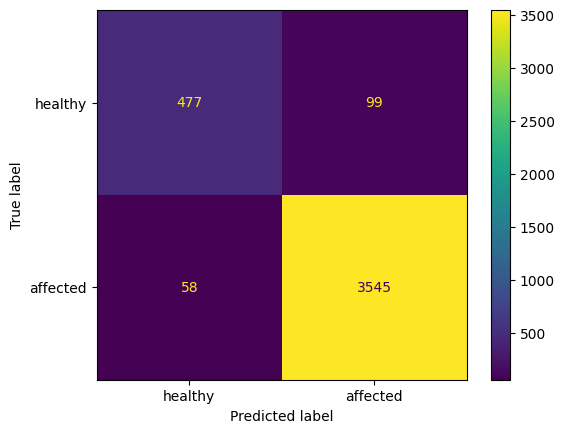

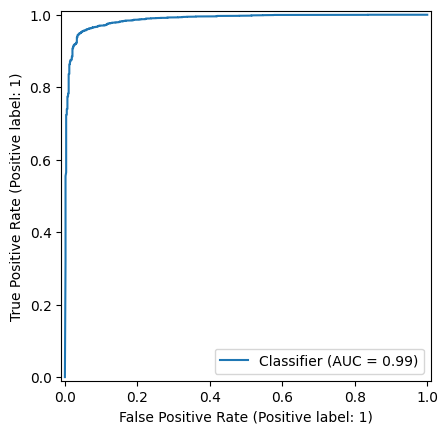

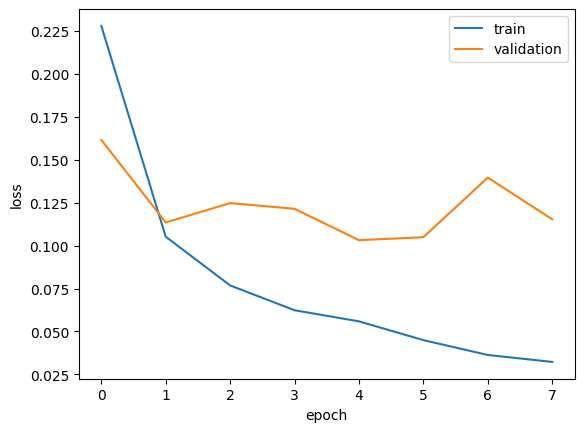

In [ ]:
test_probs = tl2.predict(test_ds).ravel()
test_pred = (test_probs >= 0.5).astype(int)

print(classification_report(y_test, test_pred, target_names=["healthy", "affected"]))
print("ROC-AUC:", roc_auc_score(y_test, test_probs))

ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["healthy", "affected"])
plt.savefig(output_dir / "disease_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

RocCurveDisplay.from_predictions(y_test, test_probs)
plt.savefig(output_dir / "disease_roc.png", dpi=150, bbox_inches="tight")
plt.show()

plt.plot(tl2_history.history["loss"], label="train")
plt.plot(tl2_history.history["val_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.savefig(output_dir / "disease_learning_curve.png", dpi=150, bbox_inches="tight")
plt.show()

On the test set the fine-tuned model reaches macro F1 0.92 and ROC-AUC 0.987, matching its validation scores (0.93 and 0.991), so the choices made on validation did not leak into the test result. Errors concentrate in the healthy class: 99 of 576 healthy leaves (17%) are flagged as affected, while 58 of 3,603 affected leaves (1.6%) are missed. For a farmer a false alarm costs an extra check but a missed disease can cost a crop, so this is the safer error pattern. The ROC curve hugs the top-left corner, and the learning curve shows training loss falling to about 0.03 while validation loss bottoms near 0.10 and then fluctuates, which is the mild overfitting seen earlier

# **10. Crop Classification (5 classes)**

### 10.1. Turn crop names into numbers and add a `crop_id` column to each table

In [ ]:
crops = sorted(all_df["crop"].unique())
crop_to_id = {c: i for i, c in enumerate(crops)}
print(crop_to_id)

train_df = train_df.assign(crop_id=train_df["crop"].map(crop_to_id))
val_df = val_df.assign(crop_id=val_df["crop"].map(crop_to_id))
test_df = test_df.assign(crop_id=test_df["crop"].map(crop_to_id))

{'cashew': 0, 'cassava': 1, 'maize': 2, 'rice': 3, 'tomato': 4}


The mapping assigns cashew = 0, cassava = 1, maize = 2, rice = 3, tomato = 4 in alphabetical order. The same order labels the axes of every crop confusion matrix and report below.

### 10.2. Pipeline that uses either label column

In [ ]:
def make_dataset(table, label_col="affected", shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((table["path"].values, table[label_col].values))
    if shuffle:
        ds = ds.shuffle(len(table), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)
    return ds

crop_train_ds = make_dataset(train_df, "crop_id", shuffle=True)
crop_val_ds = make_dataset(val_df, "crop_id")
crop_test_ds = make_dataset(test_df, "crop_id")

Adding a label-column argument lets one pipeline build the disease datasets (target "affected") and the crop datasets (target "crop_id"). The default keeps all earlier disease cells working unchanged.

### 10.3. A 5-class CNN, with a softmax output layer

In [ ]:
def build_crop_cnn(lr=0.001):
    model = keras.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        layers.Rescaling(1.0 / 255),
        layers.Conv2D(32, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dropout(0.3),
        layers.Dense(64, activation="relu"),
        layers.Dense(len(crops), activation="softmax"),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

The crop CNN uses the same architecture as the disease CNN except for a 5-unit softmax output and a categorical loss, so the baseline for the crop task is comparable to the earlier one.

### 10.4. Trains the crop baseline, logs, and scores on validation data

In [ ]:
run = wandb.init(project="summative", name="crop_cnn_baseline",
                 config={"task": "crop_id", "lr": 0.001, "dropout": 0.3, "img_size": IMG_SIZE}, reinit="finish_previous")

crop_model = build_crop_cnn()
stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
crop_history = crop_model.fit(crop_train_ds, validation_data=crop_val_ds, epochs=10, callbacks=[stop])

y_crop_val = val_df["crop_id"].values
crop_pred = crop_model.predict(crop_val_ds).argmax(axis=1)

crop_results = {
    "name": "crop_cnn_baseline",
    "accuracy": accuracy_score(y_crop_val, crop_pred),
    "macro_f1": f1_score(y_crop_val, crop_pred, average="macro"),
}
wandb.log(crop_results)
run.finish()
print(crop_results)

Epoch 1/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 52s 79ms/step - accuracy: 0.6702 - loss: 0.7931 - val_accuracy: 0.7885 - val_loss: 0.5679
Epoch 2/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 46s 76ms/step - accuracy: 0.8144 - loss: 0.4908 - val_accuracy: 0.8406 - val_loss: 0.4243
Epoch 3/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 45s 73ms/step - accuracy: 0.8673 - loss: 0.3626 - val_accuracy: 0.8693 - val_loss: 0.3528
Epoch 4/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 44s 72ms/step - accuracy: 0.9013 - loss: 0.2711 - val_accuracy: 0.8846 - val_loss: 0.3080
Epoch 5/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 44s 71ms/step - accuracy: 0.9216 - loss: 0.2161 - val_accuracy: 0.8841 - val_loss: 0.3239
Epoch 6/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 81s 70ms/step - accuracy: 0.9413 - loss: 0.1668 - val_accuracy: 0.8963 - val_loss: 0.3007
Epoch 7/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 46s 75ms/step - accuracy: 0.9551 - loss: 0.1269 - val_accuracy: 0.9013 - val_loss: 0.3045
Epoch 8/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 83s 77ms/step - accuracy: 0.9627 - loss: 0.1085 - 

accuracy,▁
macro_f1,▁
accuracy,0.8963
macro_f1,0.90745
name,crop_cnn_baseline


{'name': 'crop_cnn_baseline', 'accuracy': 0.8962962962962963, 'macro_f1': 0.9074507001634989}


The from-scratch crop CNN reaches only 0.896 accuracy and macro F1 0.907, which is low for a task that looks easy. Training accuracy climbs to 0.970 while validation accuracy stays near 0.90 and validation loss bottoms at 0.301 in epoch 6, so the model memorises its training images more than it generalises. Early stopping ended the run at epoch 9 and restored the epoch 6 weights

### 10.5 Sees which crops get confused, on validation. This cell uses `crop_model`, the baseline

131/131 ━━━━━━━━━━━━━━━━━━━━ 7s 57ms/step


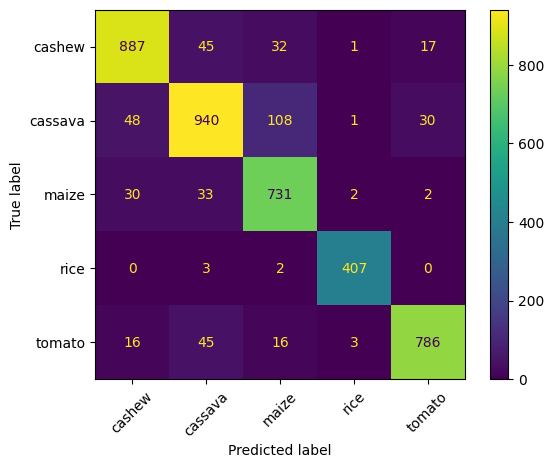

              precision    recall  f1-score   support

      cashew       0.90      0.90      0.90       982
     cassava       0.88      0.83      0.86      1127
       maize       0.82      0.92      0.87       798
        rice       0.98      0.99      0.99       412
      tomato       0.94      0.91      0.92       866

    accuracy                           0.90      4185
   macro avg       0.91      0.91      0.91      4185
weighted avg       0.90      0.90      0.90      4185



In [ ]:
crop_probs = crop_model.predict(crop_val_ds)
crop_pred = crop_probs.argmax(axis=1)

ConfusionMatrixDisplay.from_predictions(y_crop_val, crop_pred, display_labels=crops, xticks_rotation=45)
plt.show()
print(classification_report(y_crop_val, crop_pred, target_names=crops))

Most baseline errors are between the CCMT crops. The largest single confusion is cassava predicted as maize (108 images), followed by cassava and cashew mixing (48 and 45) and tomato predicted as cassava (45). Rice is almost perfect (407 of 412) even for this weak model. That fits a dataset-origin concern: rice comes from a different source with a different photographic style, so the model may be partly recognising the dataset and not only the plant

### 10.6. Experiment 2 (classification): Crop ID with TL. This is MobileNetV2 with the last 30 layers unfrozen and a softmax head

In [ ]:
def build_crop_tl(lr=0.0001, unfreeze=30):
    base = keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")
    base.trainable = True
    for layer in base.layers[:-unfreeze]:
        layer.trainable = False

    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = layers.Rescaling(1.0 / 127.5, offset=-1)(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(len(crops), activation="softmax")(x)

    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

The crop transfer model uses the same recipe as the disease one (last 30 layers unfrozen, learning rate 1e-4) with a 5-way softmax output, so differences from the baseline come mainly from pretraining

### 10.7. A helper that trains, logs, and scores a crop model, then runs the transfer experiment

In [ ]:
crop_experiments = [crop_results]

def run_crop(name, model, config, epochs=10):
    run = wandb.init(project="summative", name=name, config=config, reinit="finish_previous")
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    history = model.fit(crop_train_ds, validation_data=crop_val_ds, epochs=epochs, callbacks=[stop])

    pred = model.predict(crop_val_ds).argmax(axis=1)
    results = {
        "name": name,
        "accuracy": accuracy_score(y_crop_val, pred),
        "macro_f1": f1_score(y_crop_val, pred, average="macro"),
    }
    wandb.log(results)
    run.finish()
    crop_experiments.append(results)
    print(results)
    return model, history

crop_tl, crop_tl_history = run_crop(
    "crop_tl_mobilenetv2_finetune30",
    build_crop_tl(),
    {"task": "crop_id", "model": "mobilenetv2_finetune", "lr": 0.0001, "unfreeze": 30},
)

Epoch 1/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 71s 93ms/step - accuracy: 0.9440 - loss: 0.1609 - val_accuracy: 0.9751 - val_loss: 0.0683
Epoch 2/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 80s 101ms/step - accuracy: 0.9890 - loss: 0.0321 - val_accuracy: 0.9883 - val_loss: 0.0380
Epoch 3/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 65s 74ms/step - accuracy: 0.9952 - loss: 0.0160 - val_accuracy: 0.9871 - val_loss: 0.0388
Epoch 4/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 82s 75ms/step - accuracy: 0.9968 - loss: 0.0096 - val_accuracy: 0.9900 - val_loss: 0.0296
Epoch 5/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 49s 80ms/step - accuracy: 0.9960 - loss: 0.0108 - val_accuracy: 0.9916 - val_loss: 0.0299
Epoch 6/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 78s 74ms/step - accuracy: 0.9969 - loss: 0.0089 - val_accuracy: 0.9926 - val_loss: 0.0306
Epoch 7/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 45s 74ms/step - accuracy: 0.9981 - loss: 0.0060 - val_accuracy: 0.9916 - val_loss: 0.0280
Epoch 8/10
610/610 ━━━━━━━━━━━━━━━━━━━━ 45s 73ms/step - accuracy: 0.9978 - loss: 0.0065 -

accuracy,▁
macro_f1,▁
accuracy,0.99164
macro_f1,0.99273
name,crop_tl_mobilenetv2_...


{'name': 'crop_tl_mobilenetv2_finetune30', 'accuracy': 0.991636798088411, 'macro_f1': 0.9927339844160279}


Transfer learning lifts validation accuracy from 0.896 to 0.992 and macro F1 from 0.907 to 0.993. Training accuracy reaches about 99.7% against about 99.2% on validation, a very small gap. Validation loss bottoms at 0.028 in epoch 7, and epoch 8 shows a one-off spike (0.114) that recovers. Early stopping then ended the run at epoch 10 and restored the epoch 7 weights

# **11. Final test scoring and saving the models**


### 11.1. Scores the crop transfer model on the test set, with the confusion matrix and learning curve

131/131 ━━━━━━━━━━━━━━━━━━━━ 10s 77ms/step
accuracy: 0.9894711653505623
              precision    recall  f1-score   support

      cashew       0.99      0.99      0.99       982
     cassava       1.00      0.97      0.98      1126
       maize       0.97      1.00      0.99       790
        rice       1.00      1.00      1.00       414
      tomato       1.00      0.99      0.99       867

    accuracy                           0.99      4179
   macro avg       0.99      0.99      0.99      4179
weighted avg       0.99      0.99      0.99      4179



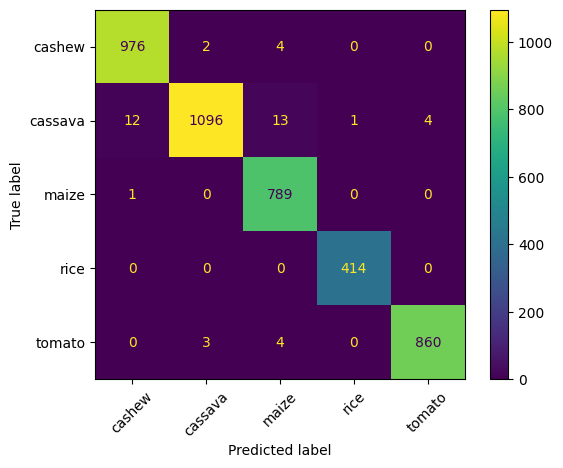

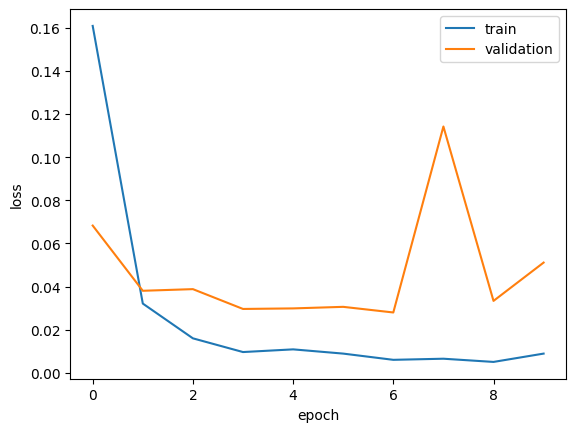

In [ ]:
y_crop_test = test_df["crop_id"].values
crop_test_pred = crop_tl.predict(crop_test_ds).argmax(axis=1)

print("accuracy:", accuracy_score(y_crop_test, crop_test_pred))
print(classification_report(y_crop_test, crop_test_pred, target_names=crops))

ConfusionMatrixDisplay.from_predictions(y_crop_test, crop_test_pred, display_labels=crops, xticks_rotation=45)
plt.savefig(output_dir / "crop_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

plt.plot(crop_tl_history.history["loss"], label="train")
plt.plot(crop_tl_history.history["val_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.savefig(output_dir / "crop_learning_curve.png", dpi=150, bbox_inches="tight")
plt.show()

Test accuracy is 0.989, close to the 0.992 on validation, so the model generalises. Cassava is the weakest crop (recall 0.97): 30 of 1,126 cassava leaves are misclassified, mostly as maize (13) and cashew (12), the same confusion pattern as the baseline but far smaller. Rice is perfect (414 of 414), which is consistent with, but does not prove, the dataset-origin concern. The learning curve shows training loss near zero and validation loss around 0.03 with one spike at epoch 8, which is the unstable epoch noted above

### 11.2. Scores the best sci-kit learn model (gradient boosting) on the test set, so this compares traditional ML and deep learning equally

In [ ]:
hgb_test_probs = hgb.predict_proba(X_test)[:, 1]
hgb_test_pred = (hgb_test_probs >= 0.5).astype(int)

print(classification_report(y_test, hgb_test_pred, target_names=["healthy", "affected"]))
print("ROC-AUC:", roc_auc_score(y_test, hgb_test_probs))

              precision    recall  f1-score   support

     healthy       0.65      0.69      0.67       576
    affected       0.95      0.94      0.95      3603

    accuracy                           0.91      4179
   macro avg       0.80      0.82      0.81      4179
weighted avg       0.91      0.91      0.91      4179

ROC-AUC: 0.9148069606346564


On the test set gradient boosting scores macro F1 0.81 and ROC-AUC 0.915, close to its validation numbers (0.806 and 0.922), so it did not overfit the validation set. It trails the fine-tuned MobileNetV2 clearly (macro F1 0.92, AUC 0.987), and the gap is largest on the healthy class (F1 0.67 against 0.86). This is the traditional versus deep learning comparison: hand-made HOG and colour features limit the classical models, while learned features do not have that limitation

### 11.3. Saves the models for the Drive folder

In [ ]:
joblib.dump(hgb, model_dir / "best_sklearn_hgb.joblib")
tl2.save(str(model_dir / "best_disease_mobilenetv2.keras"))
tl2.save(str(model_dir / "best_disease_mobilenetv2.h5"))
crop_tl.save(str(model_dir / "best_crop_mobilenetv2.keras"))
print(list(model_dir.iterdir()))

[PosixPath('/content/drive/MyDrive/summative/models/best_sklearn_hgb.joblib'), PosixPath('/content/drive/MyDrive/summative/models/best_disease_mobilenetv2.keras'), PosixPath('/content/drive/MyDrive/summative/models/best_disease_mobilenetv2.h5'), PosixPath('/content/drive/MyDrive/summative/models/best_crop_mobilenetv2.keras')]


Both model families are saved: a joblib file for the boosting model, Keras and H5 files for the disease network, and a Keras file for the crop network. The listing confirms they are in Drive

In [ ]:
import shutil

shutil.make_archive(str(raw_dir / "ccmt_raw"), "zip", work_dir / "ccmt")
shutil.make_archive(str(raw_dir / "rice_original"), "zip", work_dir / "rice")

for f in raw_dir.iterdir():
    print(f.name, round(f.stat().st_size / 1e9, 2), "GB")

ccmt_raw.zip 1.34 GB
rice_original.zip 0.41 GB


The two raw-image archives for the Drive folder are 1.34 GB (CCMT) and 0.41 GB (rice). They are much smaller than the 8.44 GB and 2.33 GB downloads because the augmented images are left out. The corrupt files remain inside the archives because they are part of the raw data, and their removal is documented in this notebook

In [ ]:
from importlib.metadata import version

packages = ["tensorflow", "scikit-learn", "scikit-image", "pandas", "numpy", "matplotlib", "pillow", "wandb", "tqdm", "joblib"]
lines = [f"{p}=={version(p)}" for p in packages]
(base_dir / "requirements.txt").write_text("\n".join(lines) + "\n")
print("\n".join(lines))

tensorflow==2.21.0
scikit-learn==1.6.1
scikit-image==0.25.2
pandas==2.2.3
numpy==2.1.3
matplotlib==3.10.0
pillow==11.3.0
wandb==0.28.1
requests==2.32.4
tqdm==4.67.3
joblib==1.6.0
